# Thirty protected areas in a single day

Today's theme asks for a map that looks old, or one whose subject is history.
This one does both: it draws **Honduras' declared protected areas by the year
they were first declared**, in the style of a hand-tinted map.

The areas come from ICF's layer of declared protected areas
[@icf-areas-protegidas-declaradas], which records each area's decree and its
date of creation (`fecha_crea`), and the country's outline from ICF's
departments layer [@icf-limite-departamentos].

In [1]:
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib import patheffects
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from pyproj import Transformer

sys.path.append("../..")  # maps/, for the shared scale bar and north arrow
from cartography import add_north_arrow, add_scale_bar

WFS = "https://geoserver.icf.gob.hn/icfpub/wfs"
CRS = 32616  # WGS 84 / UTM zone 16N, the ICF layers' own CRS, in metres


def read_layer(name: str) -> gpd.GeoDataFrame:
    """Read a layer from ICF's public WFS as GeoJSON."""
    url = (
        f"{WFS}?service=WFS&version=2.0.0&request=GetFeature"
        f"&typeNames={name}&outputFormat=application/json"
    )
    return gpd.read_file(url).to_crs(CRS)


zones = read_layer("areas_protegidas_declarada_gp")
departments = read_layer("limite_departamentos_gp")
print(f"{len(zones)} zone polygons, {zones.nomb_ap.nunique()} protected areas")

324 zone polygons, 75 protected areas


The layer splits each area into its zones (core, buffer and others). Every
zone of an area carries the same date, so the zones are merged into one shape
per area, keeping its name, category, decree and date.

In [2]:
assert (zones.groupby("nomb_ap").fecha_crea.nunique() == 1).all()

areas = zones.dissolve(
    "nomb_ap",
    aggfunc={"fecha_crea": "first", "categoria": "first", "inst_decla": "first"},
).reset_index()
areas["year"] = areas.fecha_crea.dt.year
land = departments.union_all()
print(f"{len(areas)} areas, declared from {areas.year.min()} to {areas.year.max()}")

75 areas, declared from 1961 to 2025


## When were they declared?

Counting the areas by the date of their first declaration shows one day that
stands apart from the rest: **5 August 1987**, the date of the cloud forests law
(Decreto 87-87).

The law (Ley de Bosques Nublados) declared 37 areas, according to ICF's own
fact sheets [@icf-ficha-el-pital]; in today's layer, 30 areas carry that date.

In [3]:
by_day = areas.groupby(areas.fecha_crea.dt.date).size().sort_values(ascending=False)
print(by_day.head(3).to_string())

day_8787 = areas[areas.fecha_crea == "1987-08-05"]
print(f"\n{len(day_8787)} areas on 1987-08-05:", ", ".join(sorted(day_8787.nomb_ap)))

fecha_crea
1987-08-05    30
2000-01-20    10
2010-07-26     3

30 areas on 1987-08-05: Cerro Azul, Cerro Azul Meámbar, Corralitos, Cusuco, El Armado, El Chile, El Pital, Erapuca, Guajiquiro, Güisayote, La Muralla, Misoco, Mixcure, Montaña Verde, Montaña de Celaque, Montaña de Comayagua, Montaña de Santa Bárbara, Montaña de Yoro, Montecillos, Montecristo Trifinio, Opalaca, Pico Bonito, Pico Pijol, Puca, Sabanetas, Sierra de Agalta, Texiguat, Volcán Pacayita, Yerba Buena, Yuscarán (Monserrat)


The second-largest day, 20 January 2000, is Decreto 5-99-E, which declared the
protected areas of the Gulf of Fonseca, on the Pacific coast.

The date is the one of the **first** declaration, while the shape is the
area's **current** boundary: some areas were enlarged or redrawn by later
decrees (the `inst_decla` column lists them all).

## The map

The areas are grouped in five periods, with 1987 on its own. The colors imitate
the watercolor tints of old printed maps, over a paper-colored background with
lines along the coast, a graticule and a double frame.

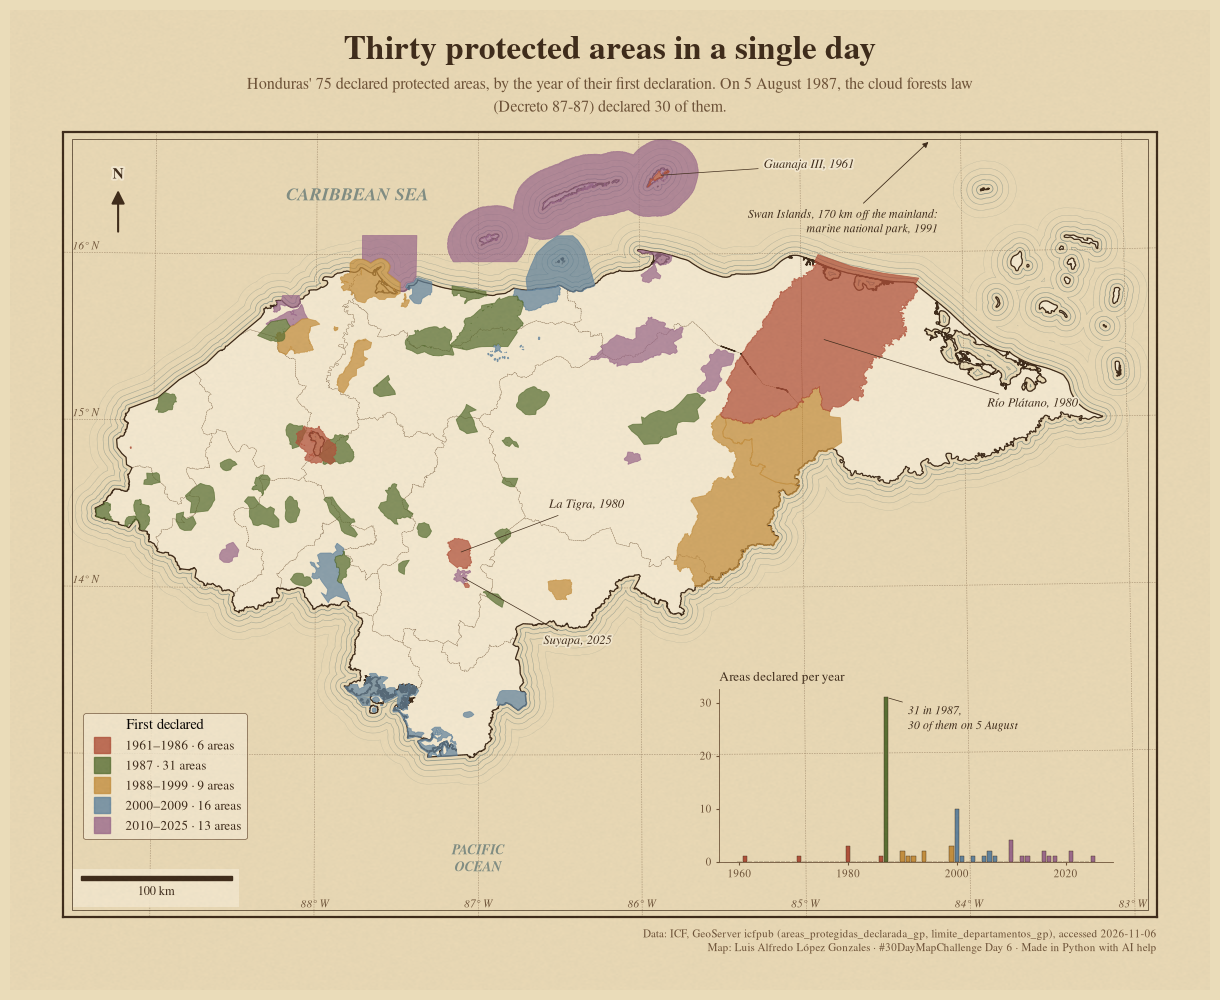

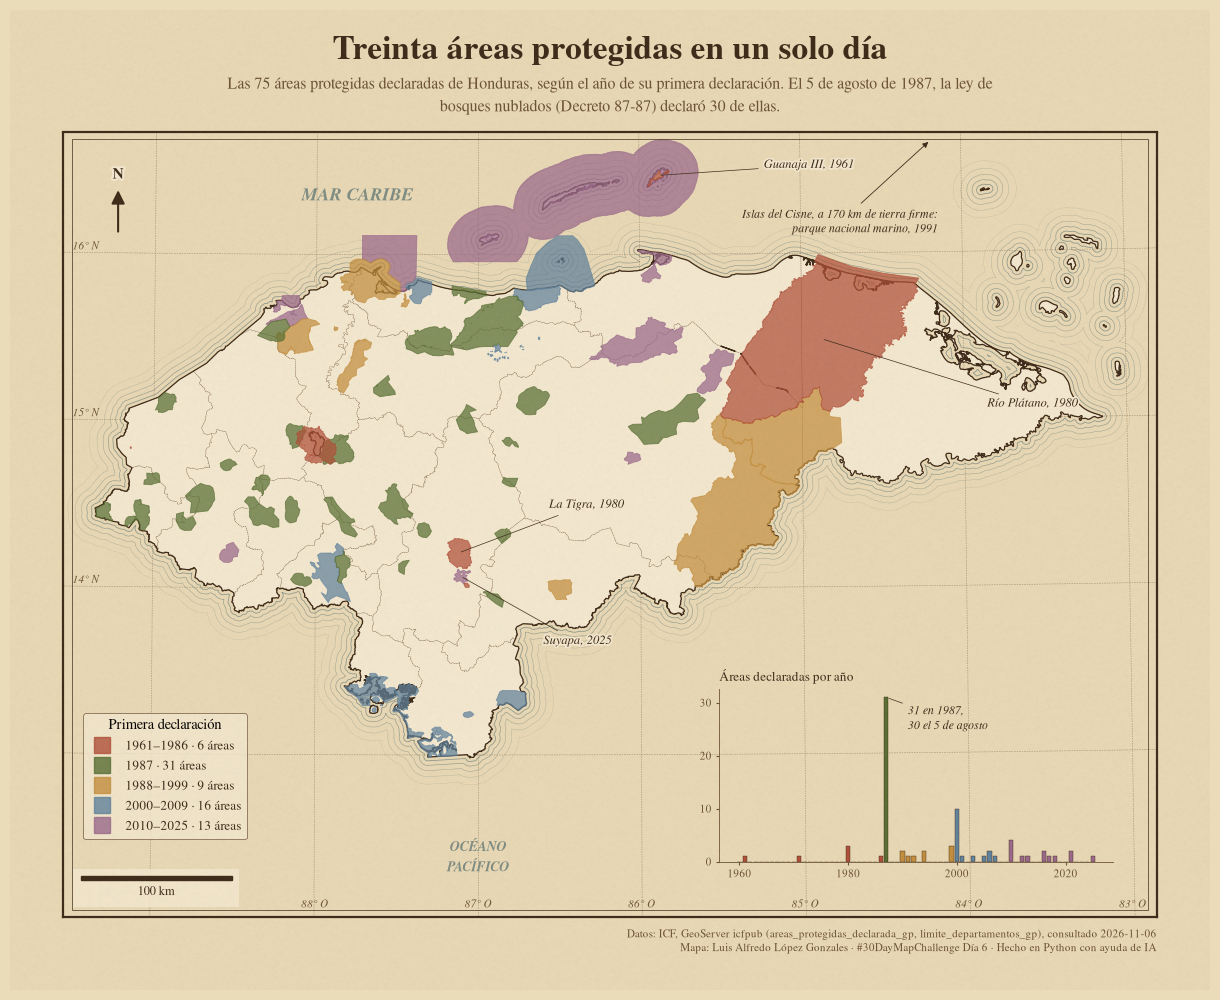

In [4]:
PERIODS = [  # (first year, last year, color)
    (1961, 1986, "#b0503a"),
    (1987, 1987, "#566f33"),
    (1988, 1999, "#c4903f"),
    (2000, 2009, "#5f84a0"),
    (2010, 2025, "#9a6a8e"),
]
PAPER, LAND, INK, INK_2, WATER = "#eadcb9", "#f5ecd4", "#3b2a1a", "#6b5238", "#7f8f86"
plt.rcParams["font.family"] = ["Nimbus Roman", "Liberation Serif", "DejaVu Serif"]


def period_of(year: int) -> int:
    """Index of the period a year falls in."""
    return next(i for i, (a, b, _) in enumerate(PERIODS) if a <= year <= b)


areas["period"] = areas.year.map(period_of)
assert areas.year.max() <= PERIODS[-1][1]
counts = areas.period.value_counts().sort_index()
per_year = areas.groupby("year").size()

# Swan Islands (Isla Santanilla o del Cisne) lie far to the north, off the frame.
SWAN = "Abogado Agustín Córdoba Rodríguez (Isla Santanilla o del Cisne)"
xlim, ylim = (225_000, 950_000), (1_330_000, 1_850_000)
swan = areas[areas.nomb_ap == SWAN].geometry.iloc[0]
mainland = max(land.geoms, key=lambda g: g.area)
swan_km = swan.distance(mainland) / 1000

LABELS = {  # area: (anchor of the label, offset in metres)
    "Guanaja III": ("1961", (70_000, 5_000)),
    "La Tigra": ("1980", (60_000, 30_000)),
    "Río Plátano": ("1980", (110_000, -45_000)),
    "Suyapa": ("2025", (55_000, -45_000)),
}

TEXT = {
    "en": {
        "title": "Thirty protected areas in a single day",
        "subtitle": (
            f"Honduras' {len(areas)} declared protected areas, by the year of their "
            f"first declaration. On 5 August 1987, the cloud forests law\n"
            f"(Decreto 87-87) declared {len(day_8787)} of them."
        ),
        "legend": "First declared",
        "areas": "{n} areas",
        "area": "{n} area",
        "chart": "Areas declared per year",
        "peak": f"{per_year[1987]} in 1987,\n{len(day_8787)} of them on 5 August",
        "swan": f"Swan Islands, {swan_km:.0f} km off the mainland:\nmarine national park, 1991",
        "sea_n": "CARIBBEAN SEA",
        "sea_s": "PACIFIC\nOCEAN",
        "credits": (
            "Data: ICF, GeoServer icfpub (areas_protegidas_declarada_gp, "
            "limite_departamentos_gp), accessed 2026-11-06\n"
            "Map: Luis Alfredo López Gonzales · #30DayMapChallenge Day 6 · "
            "Made in Python with AI help"
        ),
        "hemi": ("N", "W"),
    },
    "es": {
        "title": "Treinta áreas protegidas en un solo día",
        "subtitle": (
            f"Las {len(areas)} áreas protegidas declaradas de Honduras, según el año "
            f"de su primera declaración. El 5 de agosto de 1987, la ley de\n"
            f"bosques nublados (Decreto 87-87) declaró {len(day_8787)} de ellas."
        ),
        "legend": "Primera declaración",
        "areas": "{n} áreas",
        "area": "{n} área",
        "chart": "Áreas declaradas por año",
        "peak": f"{per_year[1987]} en 1987,\n{len(day_8787)} el 5 de agosto",
        "swan": f"Islas del Cisne, a {swan_km:.0f} km de tierra firme:\n"
        "parque nacional marino, 1991",
        "sea_n": "MAR CARIBE",
        "sea_s": "OCÉANO\nPACÍFICO",
        "credits": (
            "Datos: ICF, GeoServer icfpub (areas_protegidas_declarada_gp, "
            "limite_departamentos_gp), consultado 2026-11-06\n"
            "Mapa: Luis Alfredo López Gonzales · #30DayMapChallenge Día 6 · "
            "Hecho en Python con ayuda de IA"
        ),
        "hemi": ("N", "O"),
    },
}

HALO = [patheffects.withStroke(linewidth=2.5, foreground=LAND)]
to_utm = Transformer.from_crs(4326, CRS, always_xy=True)


def draw_water_lines(ax: plt.Axes) -> None:
    """Lines along the coast, out to sea, as engravers drew them."""
    coast = land.buffer(0)
    for i, d in enumerate([2_500, 5_500, 9_000, 13_000, 18_000]):
        ring = coast.buffer(d).boundary
        gpd.GeoSeries([ring], crs=CRS).plot(
            ax=ax, color=WATER, linewidth=0.55 - 0.08 * i, alpha=0.9 - 0.13 * i
        )


def draw_graticule(ax: plt.Axes, hemi: tuple[str, str]) -> None:
    """A 1° graticule, labelled on the frame."""
    for lon in range(-90, -82):
        lat = np.linspace(12, 18, 50)
        x, y = to_utm.transform(np.full_like(lat, lon), lat)
        ax.plot(x, y, color=INK_2, lw=0.4, ls=(0, (1, 2)), zorder=1)
        xb, _ = to_utm.transform(lon, 13.0)
        if 300_000 < xb < xlim[1]:
            ax.text(xb, ylim[0] + 6_000, f"{-lon}° {hemi[1]}", ha="center",
                    fontsize=8, color=INK_2, style="italic")
    for lat in range(12, 18):
        lon = np.linspace(-91, -82, 50)
        x, y = to_utm.transform(lon, np.full_like(lon, lat))
        ax.plot(x, y, color=INK_2, lw=0.4, ls=(0, (1, 2)), zorder=1)
        _, yb = to_utm.transform(-88.5, lat)
        if 1_500_000 < yb < ylim[1]:  # the legend covers the lower left
            ax.text(xlim[0] + 6_000, yb + 3_000, f"{lat}° {hemi[0]}", fontsize=8,
                    color=INK_2, style="italic")


def draw_chart(fig: plt.Figure, ax: plt.Axes, text: dict) -> None:
    """Areas declared per year, as a small inset in the empty south-east corner."""
    inset = ax.inset_axes([0.60, 0.07, 0.36, 0.22])
    inset.set_facecolor("none")
    years = np.arange(1960, 2026)
    values = per_year.reindex(years, fill_value=0)
    colors = [PERIODS[period_of(y)][2] if values[y] else "none" for y in years]
    inset.bar(years, values, width=0.8, color=colors, edgecolor=INK, linewidth=0.3)
    inset.annotate(
        text["peak"], xy=(1987, values[1987]), xytext=(1991, values[1987] - 6),
        fontsize=8.5, color=INK, style="italic",
        arrowprops=dict(arrowstyle="-", color=INK, lw=0.5),
    )
    inset.set_title(text["chart"], fontsize=9.5, color=INK, loc="left")
    inset.set_xticks([1960, 1980, 2000, 2020])
    inset.set_yticks([0, 10, 20, 30])
    inset.tick_params(labelsize=8, colors=INK_2, length=2)
    for side in ("top", "right"):
        inset.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        inset.spines[side].set_color(INK_2)
        inset.spines[side].set_linewidth(0.6)


def add_paper(fig: plt.Figure, seed: int = 6) -> None:
    """A faint grain over the whole sheet."""
    rng = np.random.default_rng(seed)
    grain = rng.normal(0, 1, (600, 600))
    paper = fig.add_axes([0, 0, 1, 1], zorder=10)
    paper.imshow(grain, cmap="copper", alpha=0.05, aspect="auto",
                 interpolation="bilinear")
    paper.set_axis_off()


def draw_map(lang: str) -> plt.Figure:
    """Draw the vintage map with its text in `lang` ("en" or "es")."""
    text = TEXT[lang]
    fig = plt.figure(figsize=(12, 9.8), facecolor=PAPER)
    ax = fig.add_axes([0.04, 0.075, 0.92, 0.80])
    ax.set_facecolor(PAPER)

    draw_water_lines(ax)
    draw_graticule(ax, text["hemi"])
    departments.plot(ax=ax, color=LAND, edgecolor=INK_2, linewidth=0.25,
                     linestyle=(0, (4, 2)), zorder=2)
    gpd.GeoSeries([land], crs=CRS).boundary.plot(ax=ax, color=INK, linewidth=0.9,
                                                zorder=3)
    # Newest first, so an older area stays visible where a later one overlaps it.
    for _, row in areas.sort_values("fecha_crea", ascending=False).iterrows():
        color = PERIODS[row.period][2]
        gpd.GeoSeries([row.geometry], crs=CRS).plot(
            ax=ax, color=color, alpha=0.72, edgecolor=color, linewidth=0.6, zorder=4
        )

    for name, (year, (dx, dy)) in LABELS.items():
        x, y = areas[areas.nomb_ap == name].geometry.iloc[0].representative_point().coords[0]
        ax.annotate(
            f"{name}, {year}", xy=(x, y), xytext=(x + dx, y + dy), fontsize=9,
            color=INK, style="italic", path_effects=HALO, zorder=6,
            ha="right" if dx < 0 else "left",
            arrowprops=dict(arrowstyle="-", color=INK, lw=0.5),
        )
    ax.annotate(
        text["swan"], xy=(800_000, ylim[1] - 5_000), xytext=(805_000, ylim[1] - 50_000),
        fontsize=8.5, color=INK, style="italic", ha="right", va="top", zorder=6,
        arrowprops=dict(arrowstyle="-|>", color=INK, lw=0.6),
    )
    ax.text(420_000, 1_805_000, text["sea_n"], fontsize=13, color=WATER, ha="center",
            style="italic", fontweight="bold", zorder=5)
    ax.text(500_000, 1_360_000, text["sea_s"], fontsize=10, color=WATER, ha="center",
            style="italic", fontweight="bold", zorder=5)

    handles = [
        plt.Line2D([], [], marker="s", ls="", ms=11, color=c, alpha=0.8,
                   label=(f"{a}" if a == b else f"{a}–{b}") + " · "
                   + text["areas" if counts[i] != 1 else "area"].format(n=counts[i]))
        for i, (a, b, c) in enumerate(PERIODS)
    ]
    legend = ax.legend(
        handles=handles, title=text["legend"], loc="lower left",
        bbox_to_anchor=(0.012, 0.09), frameon=True, facecolor=LAND, edgecolor=INK_2,
        fontsize=9.5, title_fontsize=10.5, labelcolor=INK,
    )
    legend.get_frame().set_linewidth(0.6)
    draw_chart(fig, ax, text)

    fig.text(0.5, 0.95, text["title"], ha="center", fontsize=24, color=INK,
             fontweight="bold")
    fig.text(0.5, 0.935, text["subtitle"], ha="center", va="top", fontsize=11.5, color=INK_2,
             linespacing=1.4)
    ax.text(1.0, -0.015, text["credits"], transform=ax.transAxes, ha="right",
            va="top", fontsize=8, color=INK_2)

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    for spine in ax.spines.values():
        spine.set_color(INK)
        spine.set_linewidth(1.6)
    ax.add_patch(Rectangle((0.008, 0.008), 0.984, 0.984, transform=ax.transAxes,
                           fill=False, edgecolor=INK, linewidth=0.5, zorder=7))
    add_scale_bar(ax, loc="lower left", color=INK, background=LAND)
    add_north_arrow(ax, xy=(0.05, 0.93), color=INK, halo=LAND)
    add_paper(fig)
    return fig


for lang in TEXT:
    fig = draw_map(lang)
    fig.savefig(f"day06-vintage-{lang}.png", dpi=200, facecolor=PAPER)
plt.show()

## References

::: {#refs}
:::